# Customer Data Preprocessing and Exploratory Data Analysis





1. Import Libraries and Load Data

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

transactions = pd.read_excel("customer_transactions.xlsx")
social = pd.read_excel("customer_social_profiles.xlsx")

print("Transactions:", transactions.shape)
print("Social profiles:", social.shape)

display(transactions.head())
display(social.head())

print("\nTransactions data types:")
print(transactions.dtypes)

print("\nSocial profiles data types:")
print(social.dtypes)


Transactions: (150, 6)
Social profiles: (155, 5)


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral



Transactions data types:
customer_id_legacy             int64
transaction_id                 int64
purchase_amount                int64
purchase_date         datetime64[ns]
product_category              object
customer_rating              float64
dtype: object

Social profiles data types:
customer_id_new             object
social_media_platform       object
engagement_score             int64
purchase_interest_score    float64
review_sentiment            object
dtype: object


I started by importing Pandas, NumPy, Matplotlib, and Seaborn for data processing and visualization. I then loaded the customer transactions and social profiles datasets.

The transactions dataset has 150 rows and 6 columns, while the social profiles dataset has 155 rows and 5 columns. I also checked the first five records and the data types to understand how the information was organized.

 Inspect data quality

In [3]:

print("Transactions missing values:")
print(transactions.isna().sum())

print("\nSocial profiles missing values:")
print(social.isna().sum())

print("\nDuplicate transaction rows:", transactions.duplicated().sum())
print("Duplicate social rows:", social.duplicated().sum())
print("Duplicate transaction IDs:", transactions["transaction_id"].duplicated().sum())
print("Duplicate social customer IDs:", social["customer_id_new"].duplicated().sum())

print("\nTransaction statistics:")
display(transactions.describe(include="all"))

print("\nSocial profile statistics:")
display(social.describe(include="all"))

Transactions missing values:
customer_id_legacy     0
transaction_id         0
purchase_amount        0
purchase_date          0
product_category       0
customer_rating       10
dtype: int64

Social profiles missing values:
customer_id_new            0
social_media_platform      0
engagement_score           0
purchase_interest_score    0
review_sentiment           0
dtype: int64

Duplicate transaction rows: 0
Duplicate social rows: 5
Duplicate transaction IDs: 0
Duplicate social customer IDs: 71

Transaction statistics:


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
count,150.000000,150.000000,150.000000,150,150,140.00000
unique,NaN,NaN,NaN,NaN,5,NaN
top,NaN,NaN,NaN,NaN,Sports,NaN
freq,NaN,NaN,NaN,NaN,35,NaN
mean,148.760000,1075.500000,280.780000,2024-03-15 12:00:00,NaN,2.98500
min,100.000000,1001.000000,51.000000,2024-01-01 00:00:00,NaN,1.00000
25%,121.250000,1038.250000,179.000000,2024-02-07 06:00:00,NaN,1.95000
50%,150.500000,1075.500000,274.000000,2024-03-15 12:00:00,NaN,3.00000
75%,174.750000,1112.750000,388.500000,2024-04-21 18:00:00,NaN,4.00000
max,199.000000,1150.000000,495.000000,2024-05-29 00:00:00,NaN,5.00000



Social profile statistics:


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
count,155,155,155.000000,155.000000,155
unique,84,5,NaN,NaN,3
top,A155,Twitter,NaN,NaN,Positive
freq,7,38,NaN,NaN,63
mean,NaN,NaN,75.606452,3.152903,NaN
std,NaN,NaN,14.568021,1.142867,NaN
min,NaN,NaN,50.000000,1.000000,NaN
25%,NaN,NaN,63.500000,2.350000,NaN
50%,NaN,NaN,77.000000,3.200000,NaN
75%,NaN,NaN,87.500000,4.100000,NaN


I checked both datasets for missing values, duplicates, and data types before cleaning them. The transaction dataset had 10 missing values in the customer rating column. I also found 5 exact duplicate records in the social profiles dataset.

These checks helped me identify the issues that needed to be handled before merging the datasets.

Clean both datasets

In [4]:

transactions = transactions.drop_duplicates().copy()
social = social.drop_duplicates().copy()

transactions["customer_id"] = (
    "A" + transactions["customer_id_legacy"].astype(str)
)

social["customer_id"] = (
    social["customer_id_new"].astype(str).str.strip().str.upper()
)

transactions["purchase_date"] = pd.to_datetime(
    transactions["purchase_date"], errors="coerce"
)

for col in ["purchase_amount", "customer_rating"]:
    transactions[col] = pd.to_numeric(
        transactions[col], errors="coerce"
    )

for col in ["engagement_score", "purchase_interest_score"]:
    social[col] = pd.to_numeric(
        social[col], errors="coerce"
    )

transactions["product_category"] = (
    transactions["product_category"].astype("string").str.strip()
)

transactions["customer_rating"] = transactions[
    "customer_rating"
].fillna(transactions["customer_rating"].median())

print("Transactions:", transactions.shape)
print("Social profiles:", social.shape)
print("Missing ratings:", transactions["customer_rating"].isna().sum())

Transactions: (150, 7)
Social profiles: (150, 6)
Missing ratings: 0


I removed exact duplicate records and filled the missing customer ratings using the median. I chose the median because it is less affected by unusually high or low values.

I also standardized the customer IDs. The transactions dataset used numerical IDs such as 151, while the social dataset used IDs such as A151. I added the letter A to the transaction customer IDs so that both datasets followed the same format.

After cleaning, the transactions dataset still had 150 records, and the social profiles dataset had 150 records.

Validate the customer IDs

In [5]:

duplicate_ids = social[
    social.duplicated("customer_id", keep=False)
].sort_values("customer_id")

print("Duplicate customer IDs:", social["customer_id"].duplicated().sum())
display(duplicate_ids)

print("Unique transaction customers:", transactions["customer_id"].nunique())
print("Unique social customers:", social["customer_id"].nunique())

Duplicate customer IDs: 66


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment,customer_id
84,A100,Instagram,81,4.4,Neutral,A100
61,A100,Twitter,73,4.4,Negative,A100
39,A103,Instagram,58,2.7,Negative,A103
38,A103,Facebook,58,3.6,Positive,A103
15,A103,Instagram,77,2.3,Positive,A103
...,...,...,...,...,...,...
64,A189,LinkedIn,78,2.7,Negative,A189
141,A197,LinkedIn,57,2.9,Neutral,A197
4,A197,Twitter,92,2.3,Neutral,A197
108,A198,Facebook,79,1.3,Negative,A198


Unique transaction customers: 75
Unique social customers: 84


After standardizing the IDs, I checked whether customers appeared more than once. I found 75 unique customers in the transactions dataset and 84 unique customers in the social profiles dataset.

The social dataset still had repeated customer IDs because some customers had more than one social media profile. These were not necessarily duplicate records, so I needed to combine their information before merging.

Summarize social profiles

In [6]:

social_clean = social.groupby("customer_id", as_index=False).agg(
    engagement_score=("engagement_score", "mean"),
    purchase_interest_score=("purchase_interest_score", "mean"),
    social_media_platform=("social_media_platform",
                           lambda x: ", ".join(sorted(x.dropna().unique()))),
    review_sentiment=("review_sentiment",
                      lambda x: x.mode().iloc[0] if not x.mode().empty else "Unknown"),
    platform_count=("social_media_platform", "nunique")
)

print("Original rows:", len(social))
print("Unique customers:", len(social_clean))
print("Duplicate IDs:", social_clean["customer_id"].duplicated().sum())

display(social_clean.head())


Original rows: 150
Unique customers: 84
Duplicate IDs: 0


,customer_id,engagement_score,purchase_interest_score,social_media_platform,review_sentiment,platform_count
0,A100,77.000000,4.400000,"Instagram, Twitter",Negative,2
1,A101,68.000000,1.000000,Twitter,Neutral,1
2,A102,51.000000,4.800000,LinkedIn,Neutral,1
3,A103,64.333333,2.866667,"Facebook, Instagram",Positive,2
4,A104,83.000000,2.933333,"Facebook, Twitter",Negative,2


To handle customers with multiple social media profiles, I grouped the records by customer ID. I calculated the average engagement and purchase interest scores, combined the different platforms, counted the number of platforms, and selected the most common review sentiment.

This reduced the social profiles data to 84 unique customers, with no repeated customer IDs. It also allowed me to keep useful information instead of deleting the additional profiles.

Merge the datasets

In [7]:

merged = transactions.merge(
    social_clean,
    on="customer_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Merge results:")
print(merged["_merge"].value_counts())

print("Transactions before:", len(transactions))
print("Rows after:", len(merged))

assert len(merged) == len(transactions)
assert merged["transaction_id"].is_unique

display(merged.head())

Merge results:
_merge
both          117
left_only      33
right_only      0
Name: count, dtype: int64
Transactions before: 150
Rows after: 150


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,customer_id,engagement_score,purchase_interest_score,social_media_platform,review_sentiment,platform_count,_merge
0,151,1001,408,2024-01-01,Sports,2.3,A151,71.666667,2.166667,"TikTok, Twitter",Neutral,2.0,both
1,192,1002,332,2024-01-02,Electronics,4.2,A192,60.000000,4.300000,Instagram,Positive,1.0,both
2,114,1003,442,2024-01-03,Electronics,2.1,A114,87.000000,4.800000,Facebook,Negative,1.0,both
3,171,1004,256,2024-01-04,Clothing,2.8,A171,NaN,NaN,NaN,NaN,NaN,left_only
4,160,1005,64,2024-01-05,Clothing,1.3,A160,72.666667,2.500000,"Instagram, LinkedIn, TikTok",Neutral,3.0,both


I merged the transactions and social profiles using the standardized customer ID. I used a left join because I wanted to keep all transaction records, including those without a matching social profile.

The merge produced 117 matched transactions and 33 unmatched transactions. The total remained 150 rows, showing that the merge did not create extra transaction records. I also used many-to-one validation to confirm that each transaction matched at most one summarized social profile.

Check the merged dataset

In [8]:

print("Missing values:")
print(merged.isna().sum())

print("\nProduct categories:")
print(merged["product_category"].value_counts())

print("\nMatched and unmatched:")
print(merged["_merge"].value_counts())

print("\nSummary statistics:")
display(merged.describe(include="all"))

Missing values:
customer_id_legacy          0
transaction_id              0
purchase_amount             0
purchase_date               0
product_category            0
customer_rating             0
customer_id                 0
engagement_score           33
purchase_interest_score    33
social_media_platform      33
review_sentiment           33
platform_count             33
_merge                      0
dtype: int64

Product categories:
product_category
Sports         35
Electronics    34
Clothing       28
Groceries      28
Books          25
Name: count, dtype: Int64

Matched and unmatched:
_merge
both          117
left_only      33
right_only      0
Name: count, dtype: int64

Summary statistics:


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,customer_id,engagement_score,purchase_interest_score,social_media_platform,review_sentiment,platform_count,_merge
count,150.000000,150.000000,150.000000,150,150,150.000000,150,117.000000,117.000000,117,117,117.000000,150
unique,NaN,NaN,NaN,NaN,5,NaN,75,NaN,NaN,18,3,NaN,2
top,NaN,NaN,NaN,NaN,Sports,NaN,A161,NaN,NaN,Twitter,Positive,NaN,both
freq,NaN,NaN,NaN,NaN,35,NaN,6,NaN,NaN,17,44,NaN,117
mean,148.760000,1075.500000,280.780000,2024-03-15 12:00:00,NaN,2.986000,NaN,74.154558,3.077208,NaN,NaN,1.598291,NaN
min,100.000000,1001.000000,51.000000,2024-01-01 00:00:00,NaN,1.000000,NaN,50.000000,1.000000,NaN,NaN,1.000000,NaN
25%,121.250000,1038.250000,179.000000,2024-02-07 06:00:00,NaN,2.100000,NaN,66.500000,2.666667,NaN,NaN,1.000000,NaN
50%,150.500000,1075.500000,274.000000,2024-03-15 12:00:00,NaN,3.000000,NaN,77.000000,3.133333,NaN,NaN,1.000000,NaN
75%,174.750000,1112.750000,388.500000,2024-04-21 18:00:00,NaN,4.000000,NaN,83.000000,3.700000,NaN,NaN,2.000000,NaN
max,199.000000,1150.000000,495.000000,2024-05-29 00:00:00,NaN,5.000000,NaN,99.000000,4.800000,NaN,NaN,4.000000,NaN


I checked the merged dataset for missing values, product category counts, and summary statistics. The missing social information for 33 transactions came from customers who had no matching social profile, rather than from an error in the merge.

I kept these records in the full merged dataset for completeness. For product prediction, I later selected only transactions with matching social profile information.

# Exploratory Data Analysis (EDA)

Purchase amount distribution

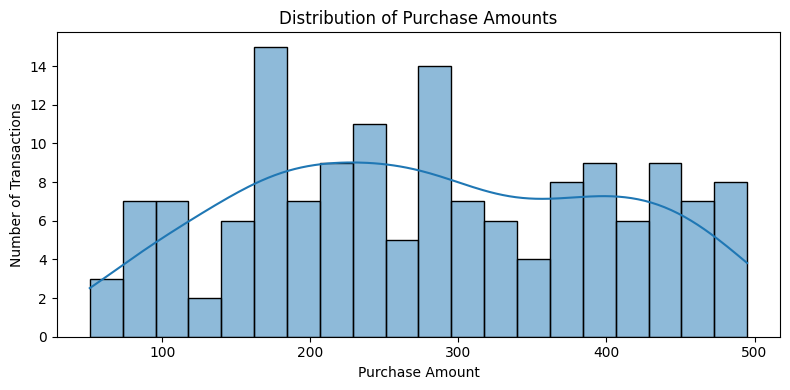

In [9]:

plt.figure(figsize=(8, 4))
sns.histplot(merged["purchase_amount"], bins=20, kde=True)
plt.title("Distribution of Purchase Amounts")
plt.xlabel("Purchase Amount")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

The histogram shows how purchase amounts are distributed across the 150 transactions. The amounts range from 51 to 495, with a mean of approximately 280.78 and a median of 274.

This shows that customers made purchases at different spending levels rather than all spending similar amounts.

Outlier analysis

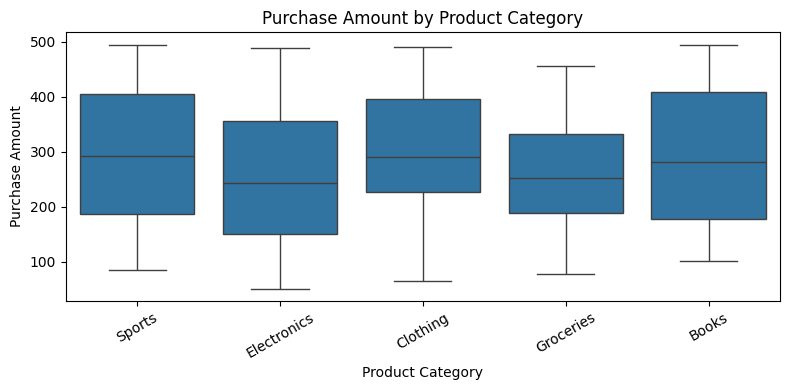

In [10]:

plt.figure(figsize=(8, 4))
sns.boxplot(data=merged, x="product_category", y="purchase_amount")
plt.title("Purchase Amount by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Purchase Amount")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

The boxplot compares purchase amounts across the different product categories. It shows the median purchase amount, the spread of the values, and any possible outliers within each category.

I used this visualization to check whether certain categories had unusually high or low purchase amounts. I did not automatically remove extreme values because they may represent genuine customer transactions.

Correlation analysis

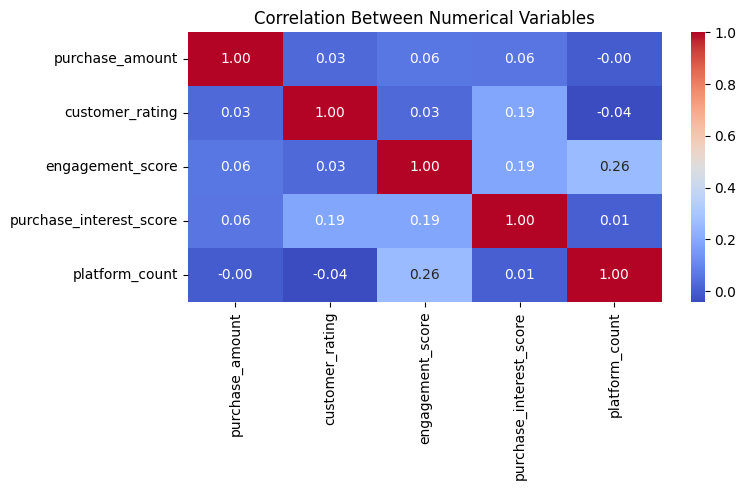

In [11]:

numeric_cols = [
    "purchase_amount",
    "customer_rating",
    "engagement_score",
    "purchase_interest_score",
    "platform_count"
]

plt.figure(figsize=(8, 5))
sns.heatmap(
    merged[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

The correlation heatmap compares the numerical variables, including purchase amount, customer rating, engagement score, purchase interest score, and platform count.

The correlation values help show whether two variables tend to increase together or move in opposite directions. I used this analysis to understand possible relationships in the dataset, but correlation does not necessarily mean that one variable causes another.

Product categories

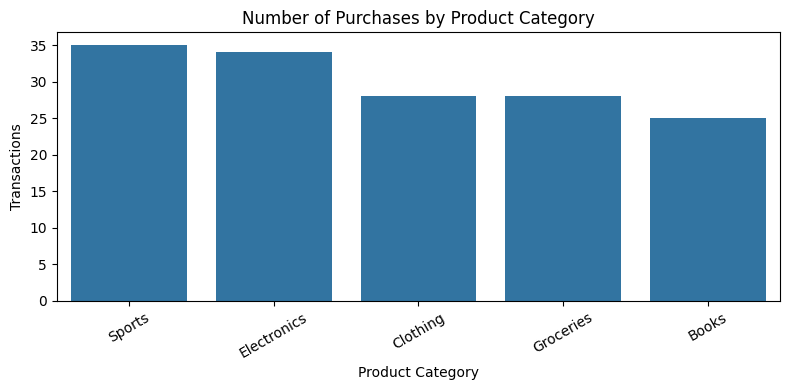

In [12]:

plt.figure(figsize=(8, 4))
sns.countplot(
    data=merged,
    x="product_category",
    order=merged["product_category"].value_counts().index
)
plt.title("Number of Purchases by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Transactions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

The count plot shows the number of transactions in each product category. Sports had the highest number of purchases with 35, followed by Electronics with 34. Clothing and Groceries each had 28 transactions, while Books had 25.

The categories are relatively balanced, although Sports and Electronics were purchased slightly more often. This is useful because product category is the target variable for our recommendation model.

Feature engineering

In [13]:

model_data = merged[merged["_merge"] == "both"].copy()

model_data["engagement_level"] = pd.cut(
    model_data["engagement_score"],
    bins=[-np.inf, 40, 70, np.inf],
    labels=["Low", "Medium", "High"]
)

model_data["interest_level"] = pd.cut(
    model_data["purchase_interest_score"],
    bins=[-np.inf, 2, 4, np.inf],
    labels=["Low", "Medium", "High"]
)

model_data = model_data[
    [
        "customer_id",
        "social_media_platform",
        "platform_count",
        "engagement_score",
        "purchase_interest_score",
        "review_sentiment",
        "engagement_level",
        "interest_level",
        "product_category"
    ]
].copy()

print("Model data shape:", model_data.shape)
print("Missing values:")
print(model_data.isna().sum())

display(model_data.head())

Model data shape: (117, 9)
Missing values:
customer_id                0
social_media_platform      0
platform_count             0
engagement_score           0
purchase_interest_score    0
review_sentiment           0
engagement_level           0
interest_level             0
product_category           0
dtype: int64


,customer_id,social_media_platform,platform_count,engagement_score,purchase_interest_score,review_sentiment,engagement_level,interest_level,product_category
0,A151,"TikTok, Twitter",2.0,71.666667,2.166667,Neutral,High,Medium,Sports
1,A192,Instagram,1.0,60.000000,4.300000,Positive,Medium,High,Electronics
2,A114,Facebook,1.0,87.000000,4.800000,Negative,High,High,Electronics
4,A160,"Instagram, LinkedIn, TikTok",3.0,72.666667,2.500000,Neutral,High,Medium,Clothing
5,A120,"Facebook, Instagram",2.0,77.000000,2.666667,Positive,High,Medium,Groceries


For the product recommendation model, I selected the 117 transactions that had matching social media profiles.

I created two additional features: engagement level and interest level. These group the numerical scores into Low, Medium, and High categories.

The final modeling dataset contains 117 rows and 9 columns. The product category is the prediction target, while the social media information is used as the input features. I excluded purchase amount, purchase date, and customer rating from the inputs because these are related to completed transactions.

Export your datasets

In [14]:

merged.to_csv("merged_customer_data.csv", index=False)
model_data.to_csv("product_model_data.csv", index=False)

print("Merged dataset:", merged.shape)
print("Product model dataset:", model_data.shape)

from google.colab import files

files.download("merged_customer_data.csv")
files.download("product_model_data.csv")

Merged dataset: (150, 13)
Product model dataset: (117, 9)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion

I completed the preprocessing of the customer transaction and social media datasets. This included checking data quality, cleaning missing and duplicate records, standardizing customer IDs, summarizing multiple social profiles, merging the datasets, and performing exploratory data analysis.

I exported two files: `merged_customer_data.csv`, containing all 150 transactions, and `product_model_data.csv`, containing the 117 matched transactions and selected features.

The product modeling dataset is ready to be used by the team member responsible for training and evaluating the recommendation model.

One limitation is that some customers have multiple transactions, so the model should be evaluated using a customer-grouped split to prevent data leakage. The social profile data also lacks timestamps, making it difficult to verify when the profile information became available.